In [2]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 878.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 63.4 MB/s eta 0:00:00


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


In [5]:

uploaded = files.upload()


Saving coin_Uniswap.csv to coin_Uniswap (1).csv
Saving coin_WrappedBitcoin.csv to coin_WrappedBitcoin.csv
Saving coin_XRP.csv to coin_XRP.csv
Saving coin_Aave.csv to coin_Aave.csv
Saving coin_BinanceCoin.csv to coin_BinanceCoin.csv
Saving coin_Bitcoin.csv to coin_Bitcoin.csv
Saving coin_Cardano.csv to coin_Cardano.csv
Saving coin_ChainLink.csv to coin_ChainLink.csv
Saving coin_Cosmos.csv to coin_Cosmos.csv
Saving coin_CryptocomCoin.csv to coin_CryptocomCoin.csv
Saving coin_Dogecoin.csv to coin_Dogecoin.csv
Saving coin_EOS.csv to coin_EOS.csv
Saving coin_Ethereum.csv to coin_Ethereum.csv
Saving coin_Iota.csv to coin_Iota.csv
Saving coin_Litecoin.csv to coin_Litecoin.csv
Saving coin_Monero.csv to coin_Monero.csv
Saving coin_NEM.csv to coin_NEM.csv
Saving coin_Polkadot.csv to coin_Polkadot.csv
Saving coin_Solana.csv to coin_Solana.csv
Saving coin_Stellar.csv to coin_Stellar.csv
Saving coin_Tether.csv to coin_Tether.csv
Saving coin_Tron.csv to coin_Tron.csv
Saving coin_USDCoin.csv to coin_

In [6]:

file_name = next(iter(uploaded.keys()))



In [7]:

df = pd.read_csv(file_name)


In [8]:

print("Dataset uploaded successfully")
print(df.shape)


Dataset uploaded successfully
(292, 10)


In [9]:

display(df.head())


,SNo,Name,Symbol,Date,High,Low,Open,Close,Volume,Marketcap
0,1,Uniswap,UNI,2020-09-18 23:59:59,8.438537,3.261757,3.488153,6.897257,6.061110e+09,6.681116e+08
1,2,Uniswap,UNI,2020-09-19 23:59:59,7.443275,5.321795,6.945577,5.724464,2.447471e+09,5.545076e+08
2,3,Uniswap,UNI,2020-09-20 23:59:59,6.050326,4.720210,5.720515,5.244195,1.554144e+09,5.079857e+08
3,4,Uniswap,UNI,2020-09-21 23:59:59,5.622155,4.160743,5.244195,4.266079,1.329464e+09,4.132392e+08
4,5,Uniswap,UNI,2020-09-22 23:59:59,4.554092,3.755040,4.275014,3.905138,8.162827e+08,3.782762e+08


In [10]:

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


In [11]:

numeric_cols = ["Open", "High", "Low", "Close", "Volume", "Marketcap"]


In [12]:

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")


In [13]:

df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)


In [14]:

df = df.dropna(subset=["Date"])


In [15]:

df = df.sort_values("Date")


In [16]:

df = df.drop_duplicates(subset=["Date"], keep="last")


In [17]:

df[numeric_cols] = df[numeric_cols].interpolate(
    method="linear", limit_direction="both"
)


In [18]:

df = df.dropna(subset=numeric_cols)


In [19]:

df = df.tail(2000).reset_index(drop=True)


In [20]:

print("Total records:", len(df))
display(df.head())


Total records: 292


,SNo,Name,Symbol,Date,High,Low,Open,Close,Volume,Marketcap
0,1,Uniswap,UNI,2020-09-18 23:59:59,8.438537,3.261757,3.488153,6.897257,6.061110e+09,6.681116e+08
1,2,Uniswap,UNI,2020-09-19 23:59:59,7.443275,5.321795,6.945577,5.724464,2.447471e+09,5.545076e+08
2,3,Uniswap,UNI,2020-09-20 23:59:59,6.050326,4.720210,5.720515,5.244195,1.554144e+09,5.079857e+08
3,4,Uniswap,UNI,2020-09-21 23:59:59,5.622155,4.160743,5.244195,4.266079,1.329464e+09,4.132392e+08
4,5,Uniswap,UNI,2020-09-22 23:59:59,4.554092,3.755040,4.275014,3.905138,8.162827e+08,3.782762e+08


In [21]:

plt.figure(figsize=(12, 5))


<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

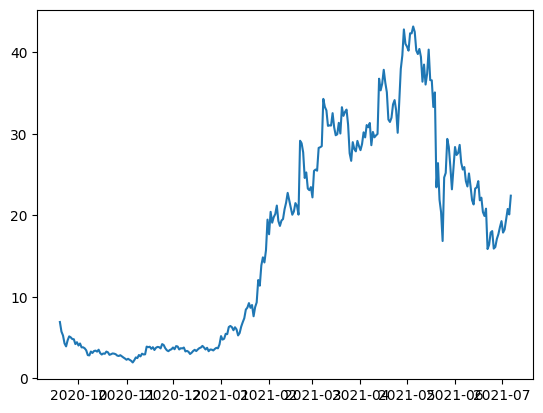

In [22]:

plt.plot(df["Date"], df["Close"])


Text(0, 0.5, 'Closing Price (USD)')

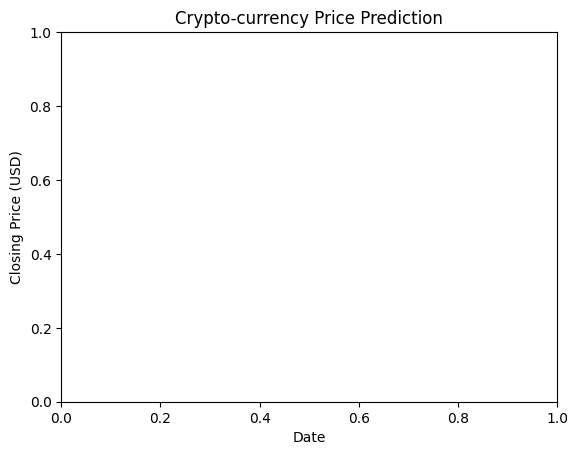

In [24]:

plt.title("Crypto-currency Price Prediction")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")


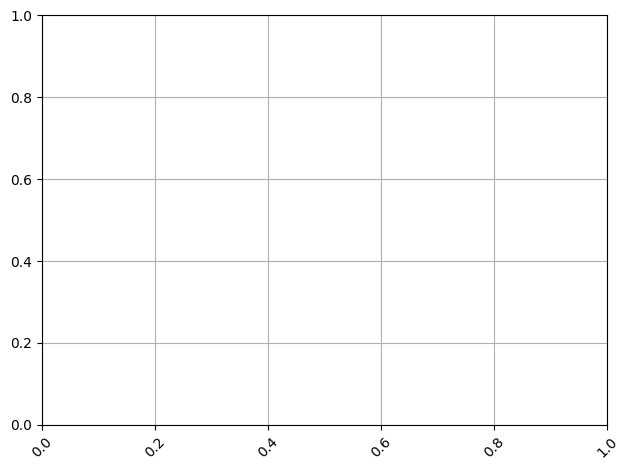

In [25]:

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [26]:

features = ["Open", "High", "Low", "Close", "Volume", "Marketcap"]


In [27]:

data = df[features].copy()


In [28]:

split_index = int(len(data) * 0.80)


In [29]:

train_data = data.iloc[:split_index]


In [30]:

test_data = data.iloc[split_index:]


In [31]:

print("Training records:", len(train_data))
print("Testing records:", len(test_data))


Training records: 233
Testing records: 59


In [32]:

feature_scaler = MinMaxScaler()


In [33]:

target_scaler = MinMaxScaler()


In [34]:

feature_scaler.fit(train_data[features])


MinMaxScaler()

In [35]:

target_scaler.fit(train_data[["Close"]])


MinMaxScaler()

In [36]:

scaled_features = feature_scaler.transform(data[features])


In [37]:

scaled_close = target_scaler.transform(data[["Close"]])


In [38]:

print(scaled_features.shape)
print(scaled_close.shape)


(292, 6)
(292, 1)


In [39]:

window_size = 7


In [40]:

X_train, y_train = [], []


In [41]:

X_test, y_test = [], []


In [42]:

for i in range(window_size, len(data)):
    X_sequence = scaled_features[i-window_size:i]
    y_target = scaled_close[i, 0]

    if i < split_index:
        X_train.append(X_sequence)
        y_train.append(y_target)
    else:
        X_test.append(X_sequence)
        y_test.append(y_target)


In [43]:

X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = np.array(X_test)
y_test = np.array(y_test)


In [44]:

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (226, 7, 6)
y_train: (226,)
X_test: (59, 7, 6)
y_test: (59,)


In [45]:

model = Sequential([
    LSTM(32, input_shape=(window_size, len(features))),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [46]:

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)


In [47]:

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,537 (21.63 KB)

 Trainable params: 5,537 (21.63 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


In [49]:

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0537 - val_loss: 0.2344
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0180 - val_loss: 0.0504
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0091 - val_loss: 0.0061
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0163 - val_loss: 0.0063
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0078 - val_loss: 0.0187
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0073 - val_loss: 0.0279
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0053 - val_loss: 0.0168
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0055 - val_loss: 0.0073


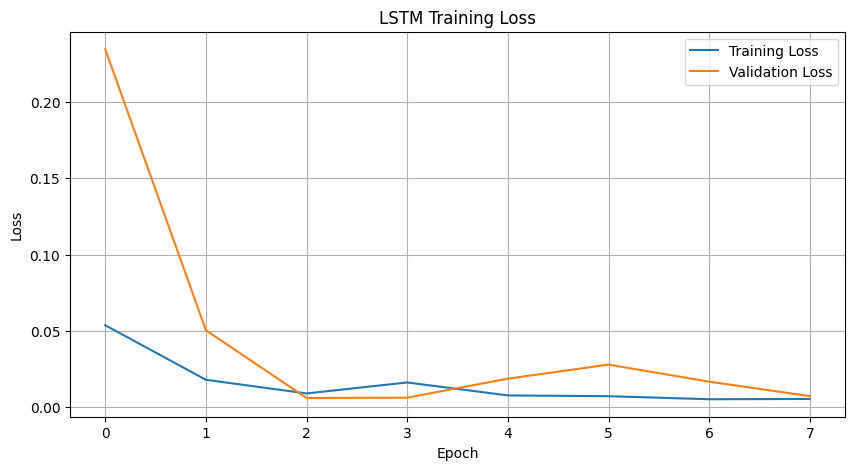

In [50]:

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [51]:

predicted_scaled = model.predict(X_test)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step


In [52]:

predicted_prices = target_scaler.inverse_transform(
    predicted_scaled
).flatten()


In [53]:

actual_prices = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()


In [54]:

results = pd.DataFrame({
    "Date": df["Date"].iloc[split_index:].to_numpy(),
    "Actual Close": actual_prices,
    "Predicted Close": predicted_prices
})


In [55]:

display(results.head(10))


,Date,Actual Close,Predicted Close
0,2021-05-09 23:59:59,39.430033,41.493626
1,2021-05-10 23:59:59,36.387953,41.292992
2,2021-05-11 23:59:59,38.489980,40.774109
3,2021-05-12 23:59:59,36.038068,40.211456
4,2021-05-13 23:59:59,37.369160,39.775848
5,2021-05-14 23:59:59,40.326213,39.507881
6,2021-05-15 23:59:59,36.577183,39.517548
7,2021-05-16 23:59:59,36.561505,39.528667
8,2021-05-17 23:59:59,33.285638,39.231461
9,2021-05-18 23:59:59,35.072030,38.833019


In [56]:

mae = mean_absolute_error(actual_prices, predicted_prices)


In [57]:

rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))


In [58]:

print("MAE:", mae)
print("RMSE:", rmse)


MAE: 4.747023537548083
RMSE: 5.76325296725461


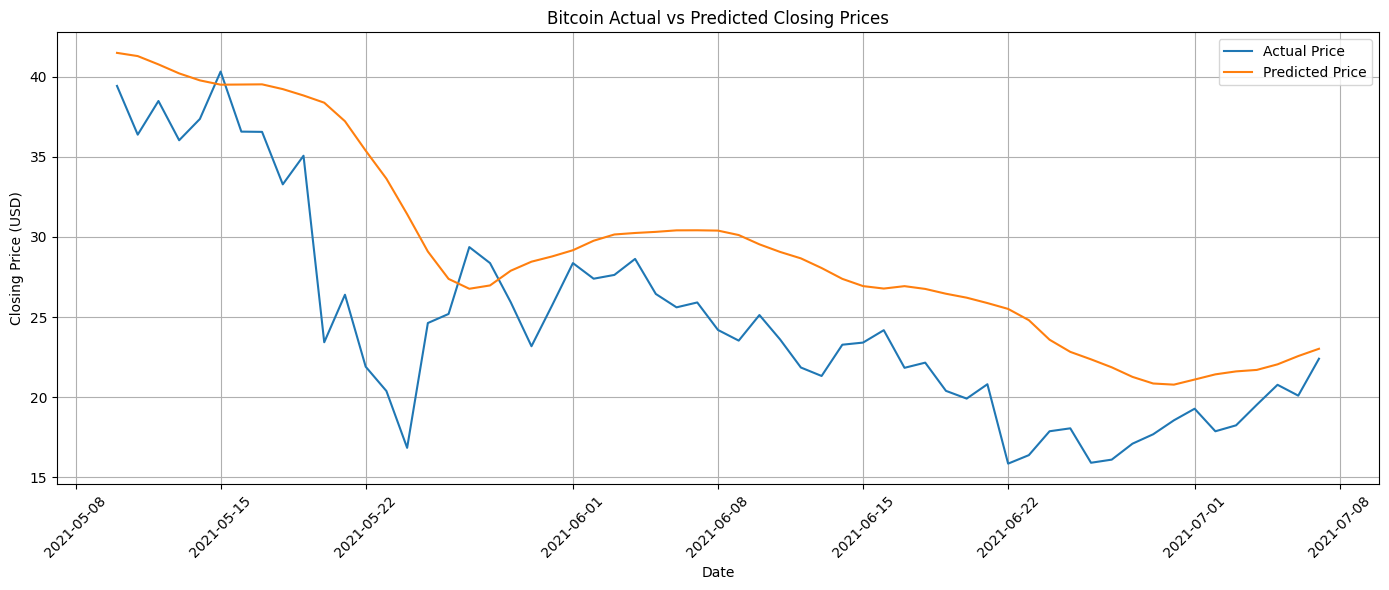

In [59]:

plt.figure(figsize=(14, 6))

plt.plot(results["Date"], results["Actual Close"],
         label="Actual Price")

plt.plot(results["Date"], results["Predicted Close"],
         label="Predicted Price")

plt.title("Bitcoin Actual vs Predicted Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [60]:

last_7_days = scaled_features[-window_size:]


In [61]:

last_7_days = last_7_days.reshape(
    1, window_size, len(features)
)


In [62]:

next_day_scaled = model.predict(last_7_days, verbose=0)


In [63]:

next_day_price = target_scaler.inverse_transform(
    next_day_scaled
)[0, 0]


In [64]:

last_date = df["Date"].iloc[-1]
next_date = last_date + pd.Timedelta(days=1)


In [65]:

print("Last available date:", last_date.date())
print("Prediction date:", next_date.date())
print(f"Predicted closing price: ${next_day_price:,.2f}")


Last available date: 2021-07-06
Prediction date: 2021-07-07
Predicted closing price: $23.49


In [67]:
import pandas as pd

print("Enter Bitcoin data for Day 1")
open1 = float(input("Open price: "))
high1 = float(input("High price: "))
low1 = float(input("Low price: "))
close1 = float(input("Close price: "))
volume1 = float(input("Volume: "))
marketcap1 = float(input("Market capitalization: "))

print("\nEnter Bitcoin data for Day 2")
open2 = float(input("Open price: "))
high2 = float(input("High price: "))
low2 = float(input("Low price: "))
close2 = float(input("Close price: "))
volume2 = float(input("Volume: "))
marketcap2 = float(input("Market capitalization: "))

data = pd.DataFrame([
    [open1, high1, low1, close1, volume1, marketcap1],
    [open2, high2, low2, close2, volume2, marketcap2]
], columns=["Open", "High", "Low", "Close", "Volume", "Marketcap"])

print("\nEntered Bitcoin Data:")
display(data)

Enter Bitcoin data for Day 1
Open price: 60000
High price: 62000
Low price: 59000
Close price: 61000
Volume: 25000000000
Market capitalization: 1200000000000

Enter Bitcoin data for Day 2
Open price: 61000
High price: 63000
Low price: 60500
Close price: 62500
Volume: 26000000000
Market capitalization: 1220000000000

Entered Bitcoin Data:


,Open,High,Low,Close,Volume,Marketcap
0,60000.0,62000.0,59000.0,61000.0,2.500000e+10,1.200000e+12
1,61000.0,63000.0,60500.0,62500.0,2.600000e+10,1.220000e+12
